<a href="https://colab.research.google.com/github/yatharthanand-code/chat-emotion-detector/blob/main/Project_02_%E2%80%94_Data_Visualization_with_Matplotlib_%26_Seaborn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

Correlation Matrix:
             total_bill   tip  size
total_bill        1.00  0.68  0.60
tip               0.68  1.00  0.49
size              0.60  0.49  1.00


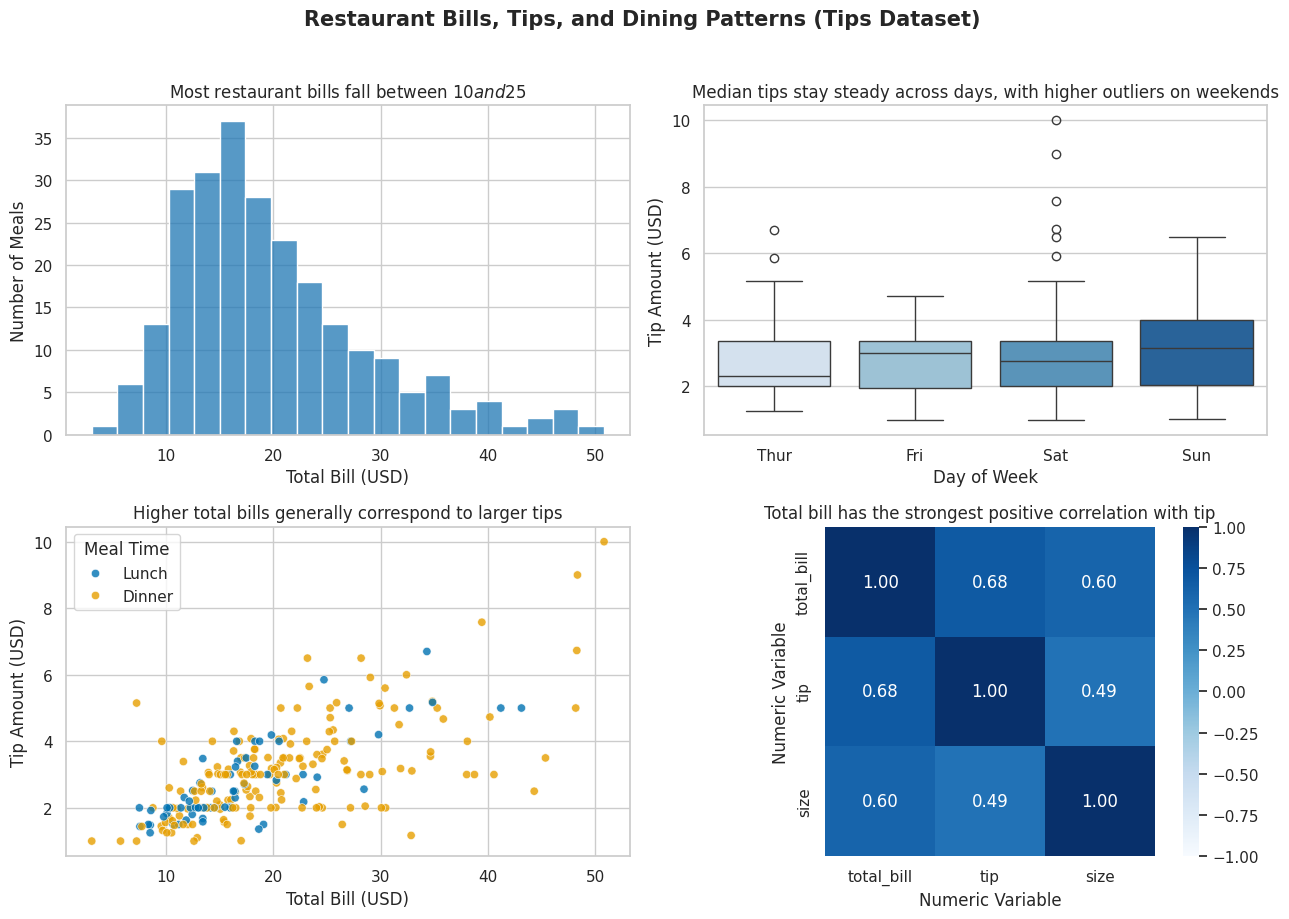


One-Line Takeaways:
- Histogram (Total Bill): Most bills sit roughly between $10 and $25, with a right skew from higher-priced meals.
- Box Plot (Tip by Day): Typical tips are fairly consistent across Thursday through Sunday, with the widest spread and highest tips on Saturday and Sunday.
- Scatter Plot (Bill vs. Tip): Larger bills tend to come with larger tips, with dinner meals making up most of the higher bill amounts.
- Heatmap (Correlations): Total bill and tip show the strongest positive correlation among numeric features, followed by total bill and party size.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load dataset & set consistent, accessible styling
tips = sns.load_dataset("tips")
sns.set_theme(style="whitegrid", palette="colorblind")

# Quick check of columns and numeric correlations
print(tips.head())
corr_matrix = tips.select_dtypes("number").corr()
print("\nCorrelation Matrix:\n", corr_matrix.round(2))

# 2. Create 2x2 dashboard figure
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Chart 1 (Top-Left): Histogram for single numeric distribution (total_bill)
sns.histplot(
    data=tips,
    x="total_bill",
    bins=20,
    color="#1f77b4",
    ax=axes[0, 0],
)
axes[0, 0].set(
    title="Most restaurant bills fall between $10 and $25",
    xlabel="Total Bill (USD)",
    ylabel="Number of Meals",
)

# Chart 2 (Top-Right): Box plot to compare groups (tip across days)
day_order = ["Thur", "Fri", "Sat", "Sun"]
sns.boxplot(
    data=tips,
    x="day",
    y="tip",
    order=day_order,
    hue="day",
    palette="Blues",
    legend=False,
    ax=axes[0, 1],
)
axes[0, 1].set(
    title="Median tips stay steady across days, with higher outliers on weekends",
    xlabel="Day of Week",
    ylabel="Tip Amount (USD)",
)

# Chart 3 (Bottom-Left): Scatter plot for two numeric variables + meaningful hue
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    palette=["#0072B2", "#E69F00"],  # Colour-blind safe blue & orange
    alpha=0.8,
    ax=axes[1, 0],
)
axes[1, 0].set(
    title="Higher total bills generally correspond to larger tips",
    xlabel="Total Bill (USD)",
    ylabel="Tip Amount (USD)",
)
axes[1, 0].legend(title="Meal Time")

# Chart 4 (Bottom-Right): Annotated correlation heatmap
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[1, 1],
)
axes[1, 1].set(
    title="Total bill has the strongest positive correlation with tip",
    xlabel="Numeric Variable",
    ylabel="Numeric Variable",
)

# 3. Layout polish & export at 150 dpi
plt.suptitle(
    "Restaurant Bills, Tips, and Dining Patterns (Tips Dataset)",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig("tips_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. One-line takeaways per chart (adapt with your own wording)
takeaways = {
    "Histogram (Total Bill)": (
        "Most bills sit roughly between $10 and $25, with a right skew from"
        " higher-priced meals."
    ),
    "Box Plot (Tip by Day)": (
        "Typical tips are fairly consistent across Thursday through Sunday,"
        " with the widest spread and highest tips on Saturday and Sunday."
    ),
    "Scatter Plot (Bill vs. Tip)": (
        "Larger bills tend to come with larger tips, with dinner meals making"
        " up most of the higher bill amounts."
    ),
    "Heatmap (Correlations)": (
        "Total bill and tip show the strongest positive correlation among"
        " numeric features, followed by total bill and party size."
    ),
}

print("\nOne-Line Takeaways:")
for chart, line in takeaways.items():
  print(f"- {chart}: {line}")